In [6]:
import pandas as pd
import numpy as np

# 1. Load the dataset (replace 'dataset.csv' with your actual file name)
df = pd.read_csv('sales_data.csv')

# 2. Inspect the first 5 rows
print("--- First 5 Rows of Dataset ---")
display(df.head())

# 3. Inspect columns, data types, and non-null counts
print("\n--- Dataset Info & Data Types ---")
df.info()

# 4. Check for duplicate rows and missing values
print(f"\nTotal duplicate rows: {df.duplicated().sum()}")
print("\nMissing values per column before cleaning:")
print(df.isnull().sum())

# 5. Data Preparation & Cleaning
# Drop duplicate records
df = df.drop_duplicates()

# Handle missing numerical values by filling with median
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Handle missing categorical values by filling with mode or 'Unknown'
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else "Unknown")

# 6. Verify cleaning results
print("\n--- Missing Values After Cleaning ---")
print(df.isnull().sum())
print(f"\nFinal Cleaned Dataset Shape: {df.shape}")

--- First 5 Rows of Dataset ---


,OrderID,CustomerName,Region,Sales,Quantity,Profit
0,101,Aarav Sharma,North,1200.50,3,150.0
1,102,Priya Patel,West,450.00,1,75.5
2,103,Rohan Verma,South,3100.25,5,600.0
3,104,Ananya Gupta,East,890.00,2,120.0



--- Dataset Info & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   OrderID       4 non-null      int64  
 1   CustomerName  4 non-null      str    
 2   Region        4 non-null      str    
 3   Sales         4 non-null      float64
 4   Quantity      4 non-null      int64  
 5   Profit        4 non-null      float64
dtypes: float64(2), int64(2), str(2)
memory usage: 388.0 bytes

Total duplicate rows: 0

Missing values per column before cleaning:
OrderID         0
CustomerName    0
Region          0
Sales           0
Quantity        0
Profit          0
dtype: int64

--- Missing Values After Cleaning ---
OrderID         0
CustomerName    0
Region          0
Sales           0
Quantity        0
Profit          0
dtype: int64

Final Cleaned Dataset Shape: (4, 6)


C:\Users\user\AppData\Local\Temp\ipykernel_12704\135559040.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object']).columns:


In [7]:
# Statistical summary for numerical columns (mean, std, min, percentiles, max)
print("--- Numerical Descriptive Statistics ---")
display(df.describe())

# Statistical summary for categorical columns (count, unique, top, freq)
print("\n--- Categorical Summary ---")
display(df.describe(include=['object']))

--- Numerical Descriptive Statistics ---


,OrderID,Sales,Quantity,Profit
count,4.000000,4.000000,4.000000,4.000000
mean,102.500000,1410.187500,2.750000,236.375000
std,1.290994,1168.023283,1.707825,244.341078
min,101.000000,450.000000,1.000000,75.500000
25%,101.750000,780.000000,1.750000,108.875000
50%,102.500000,1045.250000,2.500000,135.000000
75%,103.250000,1675.437500,3.500000,262.500000
max,104.000000,3100.250000,5.000000,600.000000



--- Categorical Summary ---


C:\Users\user\AppData\Local\Temp\ipykernel_12704\385242143.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=['object']))


,CustomerName,Region
count,4,4
unique,4,4
top,Aarav Sharma,North
freq,1,1


Matplotlib is building the font cache; this may take a moment.


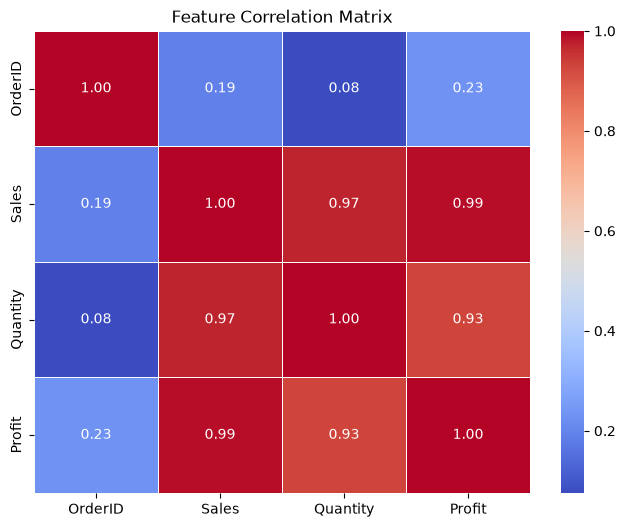

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compute correlation matrix for numerical features
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Feature Correlation Matrix")
plt.show()

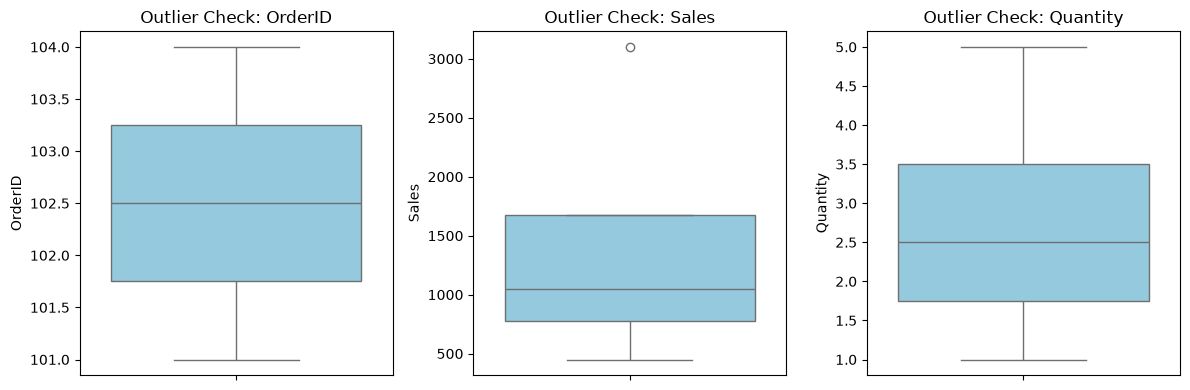

In [9]:
# Visualize outliers in key numerical columns
plt.figure(figsize=(12, 4))
num_cols = numeric_df.columns[:3] # Select first 3 numerical columns

for i, col in enumerate(num_cols, 1):
    plt.subplot(1, len(num_cols), i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f"Outlier Check: {col}")

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Create bar plot (replace 'Region' and 'Sales' with your actual column names)
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Region', palette='viridis', order=df['Region'].value_counts().index)
plt.title("Distribution of Records across Regions", fontsize=14, fontweight='bold')
plt.xlabel("Region", fontsize=12)
plt.ylabel("Count / Frequency", fontsize=12)
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Distribution plot for numerical features (e.g., Sales or Profit)
plt.figure(figsize=(10, 5))
sns.histplot(df['Sales'], kde=True, color='dodgerblue', bins=30)
plt.title("Sales Distribution and Density Curve", fontsize=14, fontweight='bold')
plt.xlabel("Sales Amount", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.show()